## PyTorchのRNNを検算してみる

In [ ]:
import torch
from torch import nn

In [ ]:
input_dim = 3
hidden_dim = 4
model = nn.RNN(
    input_size = input_dim,
    hidden_size = hidden_dim,
)

In [ ]:
model

RNN(3, 4)

In [ ]:
from pprint import pprint

In [ ]:
pprint(list(model.named_parameters()))

[('weight_ih_l0',
  Parameter containing:
tensor([[-0.0523,  0.1579,  0.1130],
        [ 0.2353,  0.0941, -0.4937],
        [ 0.3903, -0.0359, -0.3414],
        [-0.2849,  0.4452,  0.1273]], requires_grad=True)),
 ('weight_hh_l0',
  Parameter containing:
tensor([[-0.3336,  0.1242,  0.3885, -0.1253],
        [-0.4821,  0.4752, -0.0481,  0.1689],
        [-0.3096,  0.3833, -0.1140, -0.2318],
        [-0.0554,  0.1423, -0.3547, -0.1475]], requires_grad=True)),
 ('bias_ih_l0',
  Parameter containing:
tensor([ 0.0025, -0.0913,  0.2427,  0.2965], requires_grad=True)),
 ('bias_hh_l0',
  Parameter containing:
tensor([ 0.0410, -0.2403,  0.0720,  0.2446], requires_grad=True))]


In [ ]:
T = 5 # 入力する系列の長さ
batch_size = 2 # 一度に処理するデータの数
X = torch.randn(T, batch_size, input_dim) # ダミーの入力データ

In [ ]:
X

tensor([[[-1.7869,  0.9302, -0.5900],
         [ 0.4060,  1.5549,  0.0676]],

        [[-0.2595, -0.3555,  0.9267],
         [ 0.0254, -0.3976, -1.1146]],

        [[ 0.8684, -1.4696, -0.2283],
         [-1.1743, -0.3137,  0.0681]],

        [[ 0.0592, -0.6836, -0.7101],
         [ 1.4051, -0.1280,  1.1252]],

        [[ 0.2696, -0.3701, -0.1151],
         [-0.0582, -0.3095,  0.5039]]])

In [ ]:
H, hn = model(X)

In [ ]:
H.shape

torch.Size([5, 2, 4])

In [ ]:
H

tensor([[[ 2.1378e-01, -3.5686e-01, -2.1142e-01,  8.8302e-01],
         [ 2.6870e-01, -1.2252e-01,  3.7499e-01,  8.0974e-01]],

        [[-1.9999e-01, -7.6029e-01, -4.4115e-01,  4.2747e-01],
         [-2.0425e-01,  1.1766e-01,  3.4411e-01, -6.9609e-02]],

        [[-4.7172e-01, -3.1330e-01,  4.6684e-01, -3.7423e-01],
         [ 2.8055e-01, -4.9673e-01, -7.0198e-02,  5.7902e-01]],

        [[ 1.9646e-01, -3.8520e-02,  5.8116e-01,  6.9736e-04],
         [-1.7618e-01, -6.8506e-01,  7.9912e-02,  8.0065e-02]],

        [[ 1.1292e-01, -3.6876e-01,  3.1894e-01,  6.2203e-02],
         [ 4.9373e-02, -6.9319e-01, -1.0422e-01,  3.4180e-01]]],
       grad_fn=<StackBackward0>)

In [ ]:
hn

tensor([[[ 0.1129, -0.3688,  0.3189,  0.0622],
         [ 0.0494, -0.6932, -0.1042,  0.3418]]], grad_fn=<StackBackward0>)

## サイン波の予測

In [ ]:
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


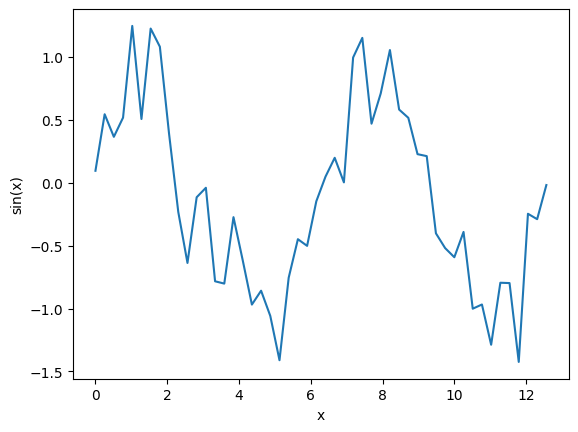

In [ ]:
# 訓練データ
x = np.linspace(0, 4*np.pi, 50)
sin_x = np.sin(x) + np.random.normal(0, 0.3, len(x))
plt.plot(x, sin_x)
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.show()

In [ ]:
# ハイパーパラメータ
n_time = 10 # 10個の時系列を1セット
n_sample = len(x) - n_time # =40

In [ ]:
# 空の配列を準備
input_data = np.zeros((n_sample, n_time, 1))
correct_data = np.zeros((n_sample, 1))

In [ ]:
# 前処理
for i in range(n_sample):
    input_data[i] = sin_x[i:i+n_time].reshape(-1, 1)
    correct_data[i] = [sin_x[i+n_time]]
input_data = torch.FloatTensor(input_data)
correct_data = torch.FloatTensor(correct_data)

In [ ]:
print(input_data.shape)

torch.Size([40, 10, 1])


In [ ]:
# バッチデータの準備
dataset = TensorDataset(input_data, correct_data)
train_loader = DataLoader(dataset, batch_size=8, shuffle=True)

In [ ]:
display(len(train_loader))
for x, t in train_loader:
    print(x.shape)
    print(t.shape)
    break

5

torch.Size([8, 10, 1])
torch.Size([8, 1])


In [ ]:
# モデルの定義
class RNN(nn.Module):
    def __init__(self): # コンストラクタを定義
        super(RNN, self).__init__()
        self.rnn = nn.RNN(1, 64, batch_first=True) # RNNのモジュール（入力1、隠れ層64）
        self.fc = nn.Linear(64, 1) # 全結合層（入力64、出力1）
    def forward(self, x):
        batch_size = x.size(0) # 入力の行数をバッチサイズに設定
        x = x.to(device) # 処理をGPUに移行
        x_rnn, hidden = self.rnn(x, None) # ?
        x = self.fc(x_rnn[:, -1, :])
        return x
model = RNN().to(device)

In [ ]:
# 最適化手法の定義
criterion = nn.MSELoss() # 平均二乗誤差
optimizer = optim.SGD(model.parameters(), lr=0.01) # 確率的勾配降下法
record_loss_train = [] # 誤差(loss)を記録する空の配列を用意

Epoch: 0 Loss_Train: 0.45950770378112793


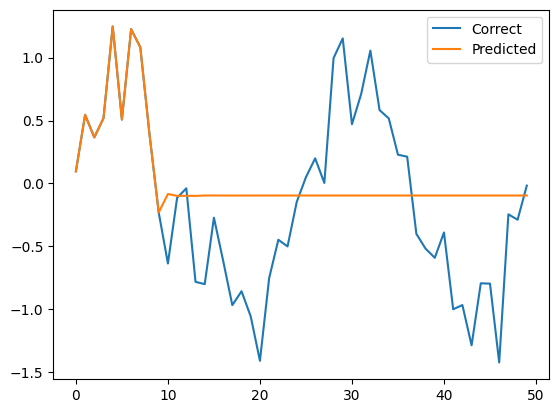

Epoch: 20 Loss_Train: 0.18451829850673676


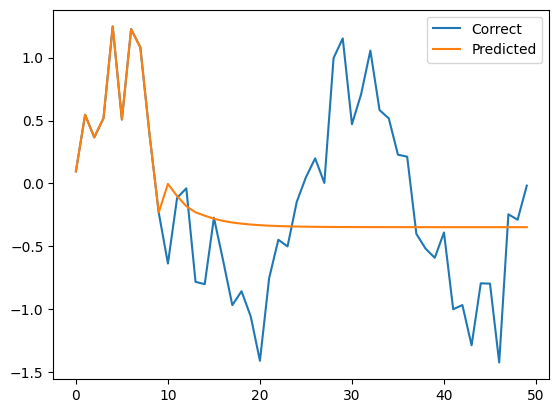

Epoch: 40 Loss_Train: 0.1526098519563675


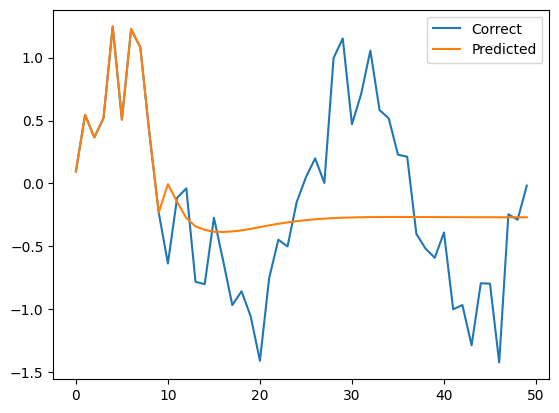

Epoch: 60 Loss_Train: 0.13445355445146562


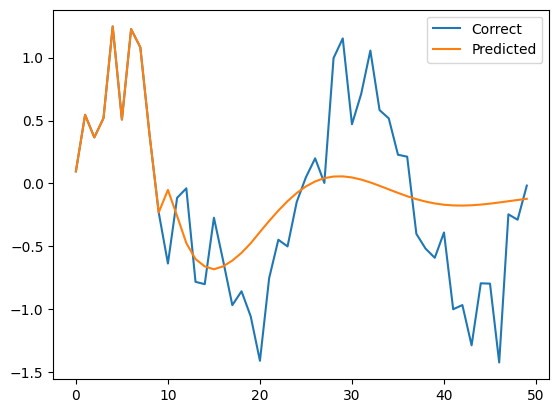

Epoch: 80 Loss_Train: 0.1278180181980133


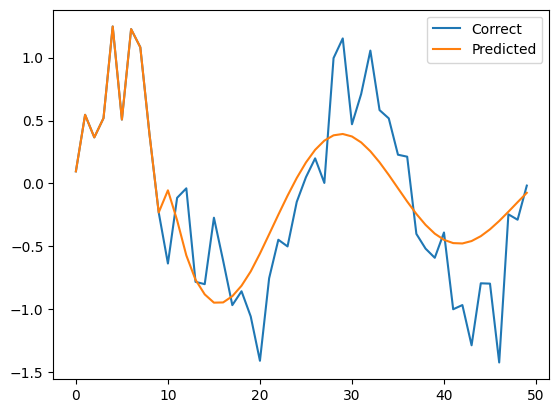

Epoch: 100 Loss_Train: 0.12254780530929565


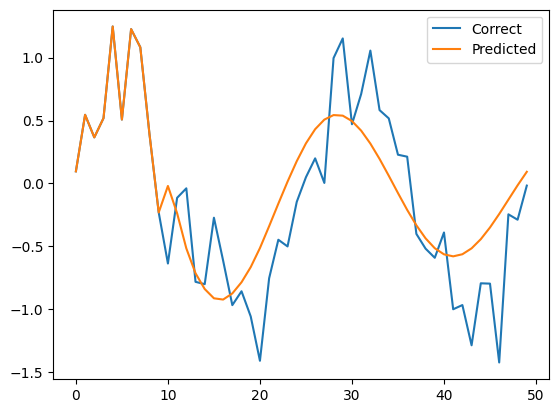

Epoch: 120 Loss_Train: 0.1200538456439972


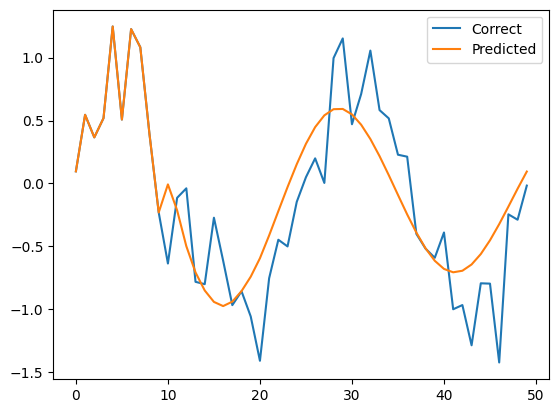

Epoch: 140 Loss_Train: 0.11700960993766785


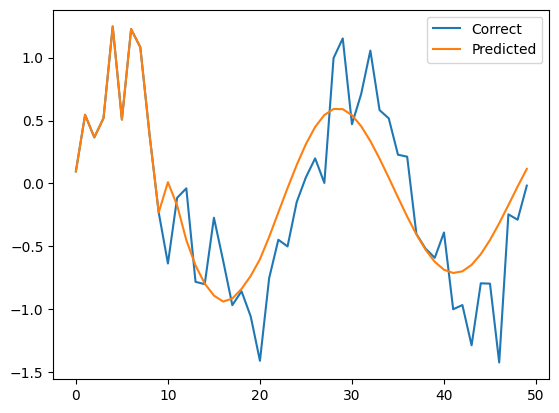

Epoch: 160 Loss_Train: 0.11230763792991638


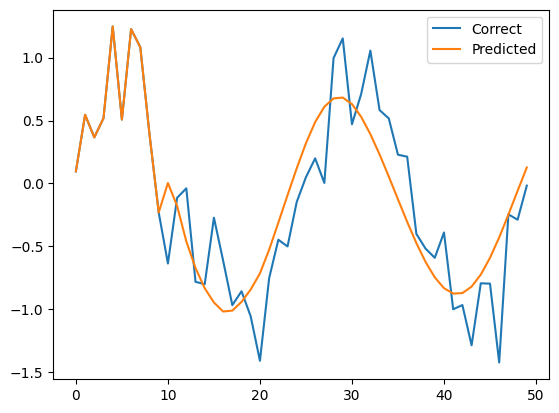

Epoch: 180 Loss_Train: 0.11081230491399766


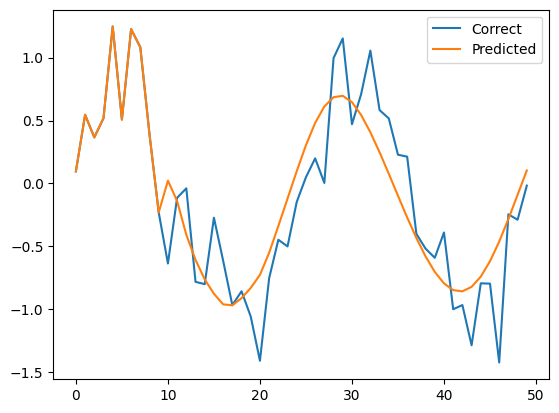

Epoch: 200 Loss_Train: 0.10757057517766952


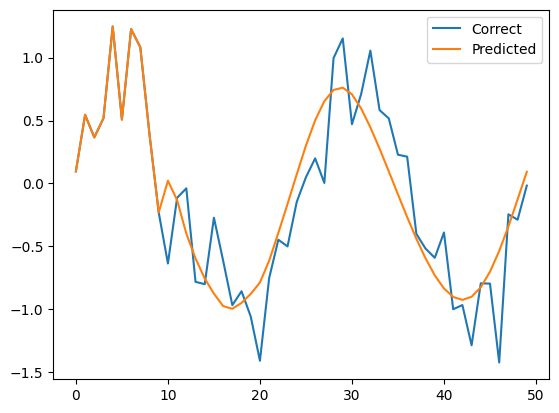

In [ ]:
for i in range(201):
  model.train() # 訓練モード
  loss_train = 0
  for j, (x, t) in enumerate(train_loader):
    loss = criterion(model(x), t.to(device))
    loss_train += loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_train /= j+1
  record_loss_train.append(loss_train)
  if i%20 == 0:
    print("Epoch:", i, "Loss_Train:", loss_train)
    predicted = list(input_data[0].reshape(-1)) # 最初のシーケンスを予測の初期値として設定する
    model.eval()
    with torch.no_grad(): # 勾配計算をしないことによって処理速度を上げる
      for i in range(n_sample):
        x = torch.tensor(predicted[-n_time:])
        x = x.reshape(1, n_time, 1)
        predicted.append(model(x)[0].item())
    plt.plot(range(len(sin_x)), sin_x, label="Correct")
    plt.plot(range(len(predicted)), predicted, label="Predicted")
    plt.legend()
    plt.show()

初めの誤差： 45.95 %
最終誤差　： 10.76  %


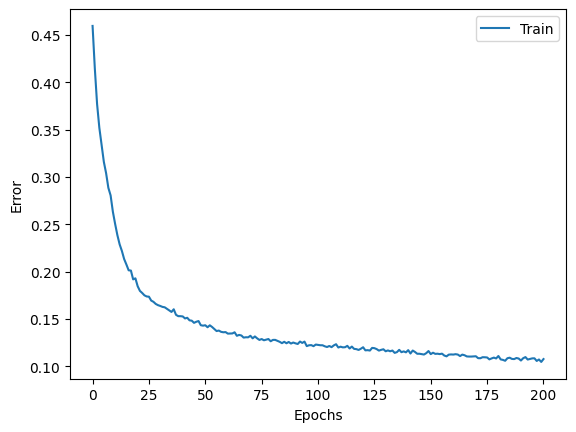

In [ ]:
'''精度の確認'''
print('初めの誤差：', round(record_loss_train[0]*100,2), '%')
print('最終誤差　：', round(record_loss_train[-1]*100,2), ' %')
plt.plot(range(len(record_loss_train)), record_loss_train, label='Train')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()